# Neural Networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hamedheli/ml-from-scratch/blob/main/04-neural-networks/neural_networks.ipynb) [![View in nbviewer](https://img.shields.io/badge/view%20in-nbviewer-orange)](https://nbviewer.org/github/HamedHeli/ml-from-scratch/blob/main/04-neural-networks/neural_networks.ipynb)

Part of [Machine Learning From Scratch](../README.md). The code for this model is in this folder; shared helpers (data loading, plotting, loss functions) are in [`common/`](../common).


## Setup

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    # On Colab, get the code and data from GitHub first
    if not Path("/content/ml-from-scratch").exists():
        !git clone -q https://github.com/hamedheli/ml-from-scratch.git /content/ml-from-scratch
    ROOT = Path("/content/ml-from-scratch")
else:
    ROOT = Path.cwd().resolve().parent  # this notebook sits in one model folder

# shared helpers, plus the model folders this notebook uses
for folder in ["common", "03-gradient-descent", "04-neural-networks"]:
    sys.path.insert(0, str(ROOT / folder))


In [2]:
import gzip
import pickle
import time

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer

from utils import DATA_DIR, load_dataset, plot_classifier, standardize_cols
from fun_obj import MLPLogisticRegressionLossL2
from linear_models import LinearModelMultiOutput
from optimizers import GradientDescent, GradientDescentLineSearch, StochasticGradient
from learning_rate_getters import ConstantLR, InverseSqrtLR
from layers import NonLinearEncoderMultiLayer
from neural_net import NeuralNet

plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(0)  # makes the random initializations (and the numbers quoted below) reproducible


A fully-connected network passes the input through hidden layers $z^{(l)} = h(W^{(l)} z^{(l-1)} + b^{(l)})$, with the sigmoid activation $h(a) = 1/(1+e^{-a})$. A linear output layer and a softmax come after the hidden layers. Training minimizes the softmax cross-entropy plus an L2 penalty on all the weights $w$:
$$f(w) = -\sum_{i=1}^{n} \log \frac{\exp(\hat y_{i,y_i})}{\sum_{c} \exp(\hat y_{ic})} + \frac{\lambda}{2}\|w\|^2$$
There is no automatic differentiation here. The gradient for every layer is computed by backpropagation, written by hand.

**What I implemented**
* `NonLinearEncoderMultiLayer` ([`layers.py`](layers.py)): the stack of sigmoid layers.
* `LinearModelMultiOutput` ([`linear_models.py`](../03-gradient-descent/linear_models.py)): the linear output layer.
* `MLPLogisticRegressionLossL2` ([`fun_obj.py`](../common/fun_obj.py)): forward pass, softmax loss, backpropagation through every layer using $h'(a) = h(a)(1-h(a))$, and the L2 penalty.
* `NeuralNet` ([`neural_net.py`](neural_net.py)): ties the layers, the loss and the optimizer together.

**Data**
* MNIST: 28×28 grayscale handwritten digits, 50,000 for training and 10,000 for validation, flattened to 784 pixels.
* `sinusoids`: a synthetic 2-D dataset with two classes separated by a sine-shaped boundary, so it is not linearly separable.

## 1. Forward pass by hand
A quick check of the forward pass for one hidden layer with sigmoid activations:

* Hidden-layer weights $W = \begin{bmatrix} -2 & -1 & 3 \\ 1 & 0 & -2 \end{bmatrix}$
* Output weights $v = \begin{bmatrix} 4 \\ 2 \end{bmatrix}$
* Input $x_i = \begin{bmatrix} 4 \\ -2 \\ 2 \end{bmatrix}$

1. Hidden-layer input: $z_i = W x_i = \begin{bmatrix} -8 + 2 + 6 \\ 4 + 0 - 4 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$
2. Activation: $h(z_i) = \begin{bmatrix} 0.5 \\ 0.5 \end{bmatrix}$, since $h(0) = 0.5$
3. Prediction: $\hat{y}_i = v^\top h(z_i) = 4 \times 0.5 + 2 \times 0.5 = 3$

The same computation in NumPy:

In [3]:
W = np.array([[-2, -1, 3], [1, 0, -2]])
v = np.array([4, 2])
x_i = np.array([4, -2, 2])

z_i = W @ x_i
h_z = 1 / (1 + np.exp(-z_i))
print("z =", z_i, "  h(z) =", h_z, "  y_hat =", v @ h_z)

z = [0 0]   h(z) = [0.5 0.5]   y_hat = 3.0


## 2. MNIST digit classification
The architecture is 784 → 128 → 64 → 10 sigmoid layers, then a linear 10 → 10 output layer with a softmax. Pixels are standardized. Training uses mini-batch SGD with a batch size of 500, a constant learning rate of $10^{-3}$, 20 epochs, and $\lambda = 0.1$.

In [4]:
with gzip.open(DATA_DIR / "mnist.pkl.gz", "rb") as f:
    train_set, valid_set, test_set = pickle.load(f, encoding="latin1")

X_train, y_train = train_set
X_valid, y_valid = valid_set


mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0) + 1e-8   # avoid division by zero

X_train = (X_train - mu) / sigma
X_valid = (X_valid - mu) / sigma

# Use these for training our MLP classifier
binarizer = LabelBinarizer()
Y_train = binarizer.fit_transform(y_train)

n, d = X_train.shape
_, k = Y_train.shape  # k is the number of classes


# Assemble a neural network
# put hidden layer dimensions to increase the number of layers in encoder
hidden_feature_dims = [128, 64]
output_dim = 10

# First, initialize an encoder and a predictor
layer_sizes = [d, *hidden_feature_dims, output_dim]
encoder = NonLinearEncoderMultiLayer(layer_sizes)
predictor = LinearModelMultiOutput(output_dim, k)

# Function object will associate the encoder and the predictor during training
fun_obj = MLPLogisticRegressionLossL2(encoder, predictor, .1)

# Choose optimization strategy
child_optimizer = GradientDescent()
learning_rate_getter = ConstantLR(1e-3)
#learning_rate_getter = InverseSqrtLR (1e-1)
optimizer = StochasticGradient(
    child_optimizer,
    learning_rate_getter,
    500,
    max_evals=20
)

# Assemble!
model = NeuralNet(fun_obj, optimizer, encoder, predictor, classifier_yes=True)

t = time.time()
model.fit(X_train, Y_train)
print("Fitting took {:f} seconds".format((time.time() - t)))

# Compute training error
y_hat = model.predict(X_train)
err_train = np.mean(y_hat != y_train)
print("Training error = ", err_train)

# Compute validation error
y_hat = model.predict(X_valid)
err_valid = np.mean(y_hat != y_valid)
print("Validation error     = ", err_valid)

Fitting took 68.244434 seconds


Training error =  0.0331
Validation error     =  0.0511


The network gets about 3.3% training error and 5.1% validation error, or roughly 95% accuracy on digits it has never seen. The gap between training and validation error is small, so the network is not overfitting much. All of it is built from NumPy matrix products and the hand-written gradients.

## 3. What the hidden layers learn
The sinusoid data can't be separated by a straight line in its original 2-D space. Here the network's last hidden layer has 2 units, so the learned features $z$ can be plotted directly. The plots show whether the network has transformed the data into something the linear output layer *can* separate.

I compare three encoders: 2 → **4** → 2, 2 → **2** → 2, and 2 → **2 → 2** → 2. Training uses gradient descent with line search and no regularization. The loss is non-convex, so for each architecture I train 20 random initializations with 10 warm restarts each, and keep the model with the lowest validation error.

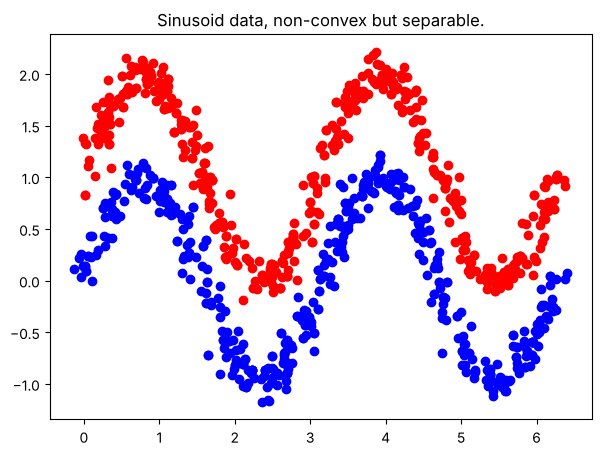


Running with hidden dimensions=[4], output dimension=2


Best validation error = 0.002


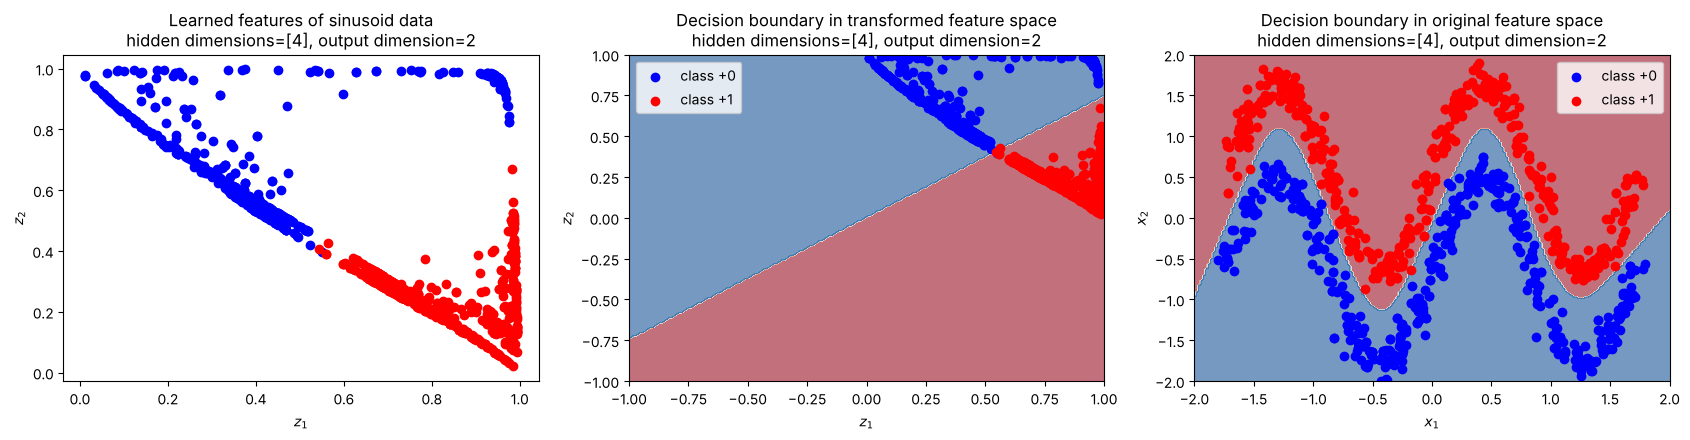


Running with hidden dimensions=[2], output dimension=2


Best validation error = 0.181


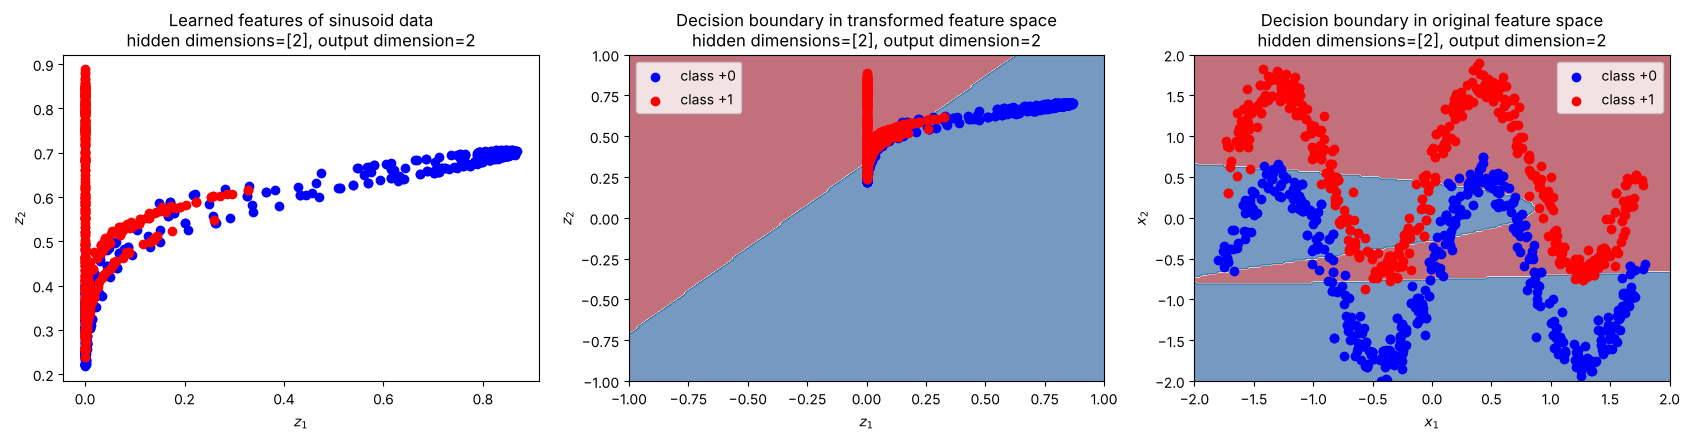


Running with hidden dimensions=[2, 2], output dimension=2


Best validation error = 0.198


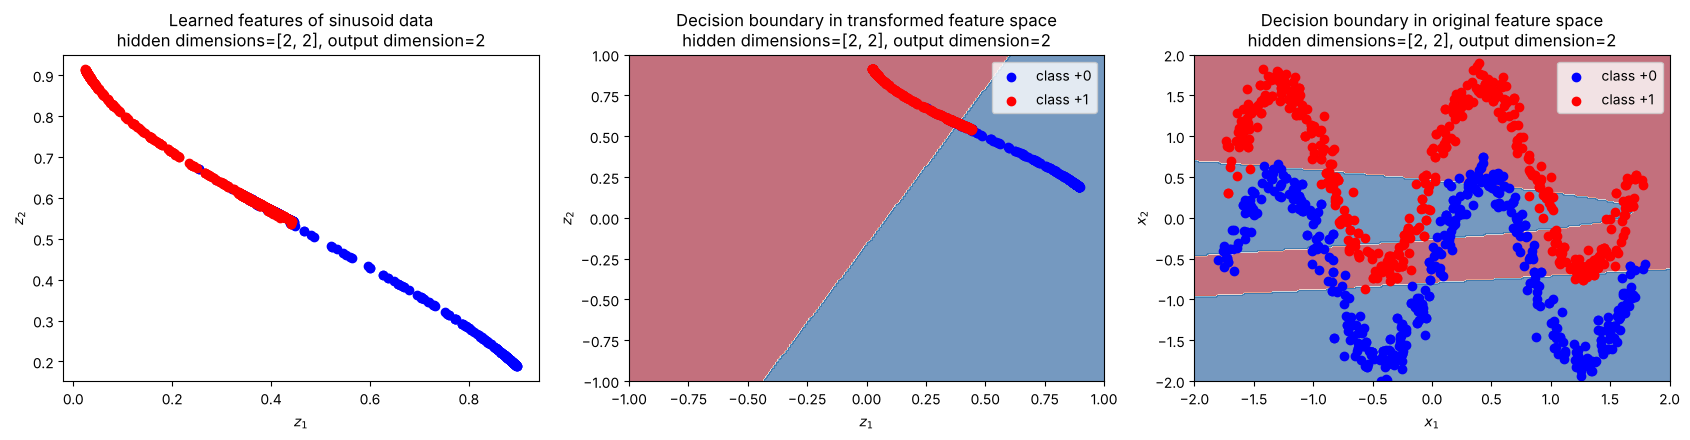

In [5]:
data = load_dataset("sinusoids.pkl")
X_train = data["X_train"]
y_train = data["y_train"]
X_valid = data["X_valid"]
y_valid = data["y_valid"]

n, d = X_train.shape
k = len(np.unique(y_train))

Y_train = np.stack([1 - y_train, y_train], axis=1).astype(np.uint)

fig, ax = plt.subplots()
for c, color in [(0, "b"), (1, "r")]:
    in_c = y_train == c
    ax.scatter(X_train[in_c, 0], X_train[in_c, 1], color=color, label=f"class {c}")
ax.set_title("Sinusoid data, non-convex but separable.")
plt.show()

X_train_standardized, mu, sigma = standardize_cols(X_train)
X_valid_standardized, _, _ = standardize_cols(X_valid, mu, sigma)

for hidden_feature_dims in [[4], [2], [2, 2]]:
    # We're running this several times, for different encoder architectures.
    output_dim = 2
    layer_sizes = [d, *hidden_feature_dims, output_dim]

    title = (
        f"hidden dimensions={hidden_feature_dims}, output dimension={output_dim}"
    )
    fn_suffix = f"{hidden_feature_dims}_{output_dim}"
    print("\nRunning with " + title)

    # for reproducibility of the solution
    np.random.seed(10)

    best_err_valid = np.inf
    best_model = None
    for seed in range(20):  # "grid search over random seeds"
        # First, initialize an encoder and a predictor
        encoder = NonLinearEncoderMultiLayer(layer_sizes)
        predictor = LinearModelMultiOutput(output_dim, k)
        fun_obj = MLPLogisticRegressionLossL2(encoder, predictor, 0.0)
        optimizer = GradientDescentLineSearch()
        model = NeuralNet(
            fun_obj, optimizer, encoder, predictor, classifier_yes=True
        )
        for _ in range(10):
            # "continual warm-start with resets":
            # one brute-force method to fight NP-hard problems!
            # calling fit() will reset the optimizer state,
            # but the encoder and predictor's parameters will stay intact.
            model.fit(X_train_standardized, Y_train)

            # Comput training error
            y_hat = model.predict(X_train_standardized)
            err_train = np.mean(y_hat != y_train)

            # Compute validation error
            y_hat = model.predict(X_valid_standardized)
            err_valid = np.mean(y_hat != y_valid)

            if err_valid < best_err_valid:
                best_err_valid = err_valid
                best_model = model

                # print("Training error = ", err_train)
                # print("Validation error     = ", err_valid)

    print(f"Best validation error = {best_err_valid:.3f}")

    # Visualize learned features
    Z_train, _ = best_model.encode(X_train_standardized)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    ax = axes[0]
    for c, color in [(0, "b"), (1, "r")]:
        in_c = y_train == c
        ax.scatter(
            Z_train[in_c, 0], Z_train[in_c, 1], color=color, label=f"class {c}"
        )
    ax.set_xlabel("$z_{1}$")
    ax.set_ylabel("$z_{2}$")
    ax.set_title("Learned features of sinusoid data\n" + title)

    ax = axes[1]
    plot_classifier(best_model.predictor, Z_train, y_train, need_argmax=True, ax=ax)
    ax.set_xlabel("$z_{1}$")
    ax.set_ylabel("$z_{2}$")
    ax.set_title("Decision boundary in transformed feature space\n" + title)

    ax = axes[2]
    plot_classifier(best_model, X_train_standardized, y_train, ax=ax)
    ax.set_xlabel("$x_{1}$")
    ax.set_ylabel("$x_{2}$")
    ax.set_title("Decision boundary in original feature space\n" + title)
    fig.tight_layout()
    plt.show()

* **2 → 4 → 2** (validation error 0.2%): the left plot shows the network has pulled the two sine-shaped classes into two separate regions of the $z$ space, and the linear output layer splits them with a straight line. Mapped back to the input space, that straight line becomes the curved boundary on the right, which follows the sine curve.
* **2 → 2 → 2** (18.1%) and **2 → 2 → 2 → 2** (19.8%): with only two hidden units per layer, the network can't unfold the data. Both classes are squeezed onto the same thin curve in $z$ space, so no straight line separates them, and the boundary in input space misses large parts of the curve. Adding a second narrow layer doesn't help.

The width of the hidden layer matters more here than the depth. The network needs enough hidden units to bend the data into a shape where a linear classifier can do the rest.